# Example of the aitlas toolbox in the context of multi class image classification

The SatlasPretrain dataset being very large, this notebook showcases an example on a subset of the dataset. The dataset can be used for image classification or semantic segmentation. We here consider the image classification task using the dynamic labels.

## Import the required packages

In [ ]:
from aitlas.datasets import SatlasPretrainImageClassificationDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/satlaspretrain_image_classification/",
}
dataset = SatlasPretrainImageClassificationDataset(dataset_config)
print(len(dataset))

582


## Show images from the dataset

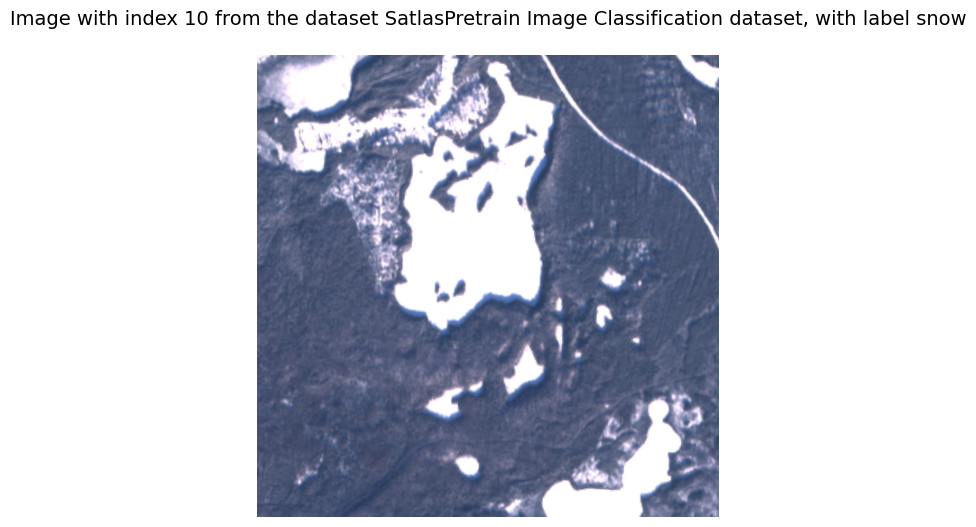

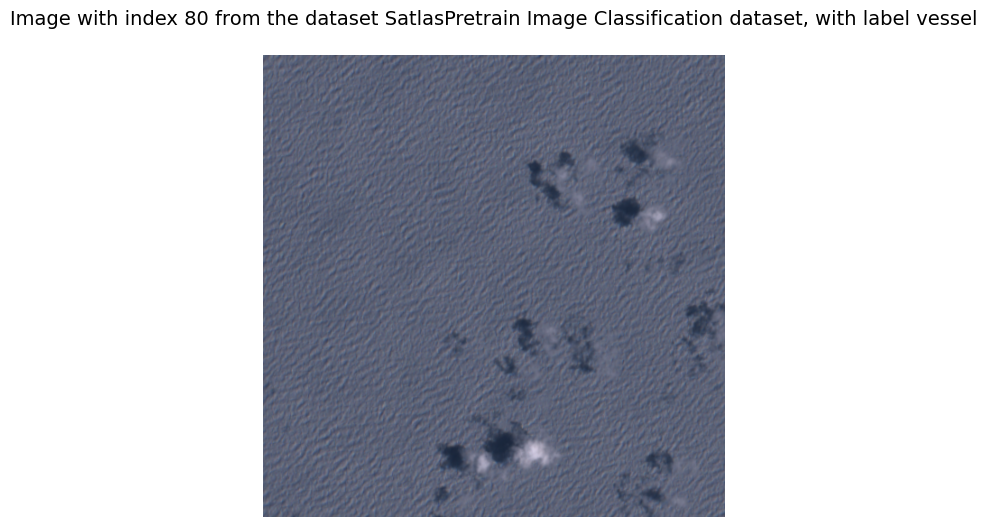

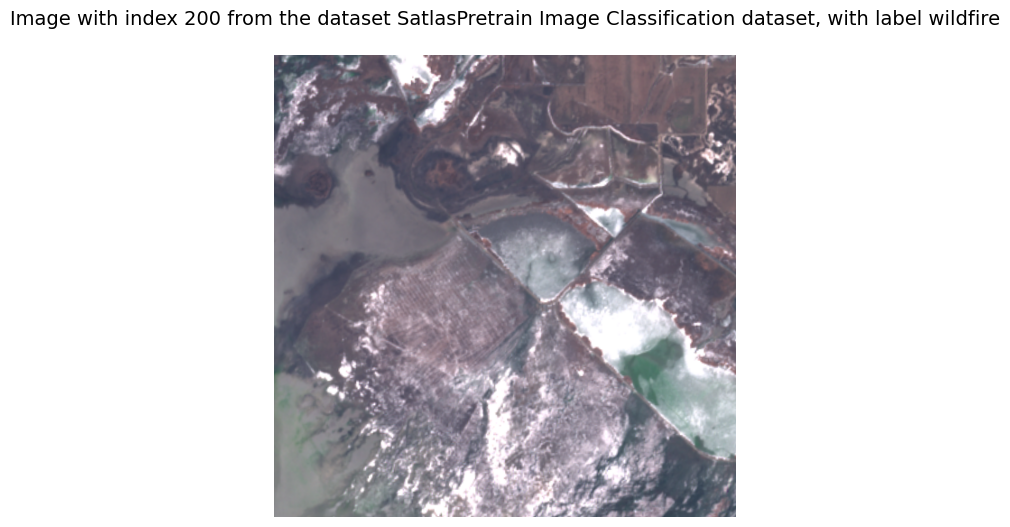

In [6]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

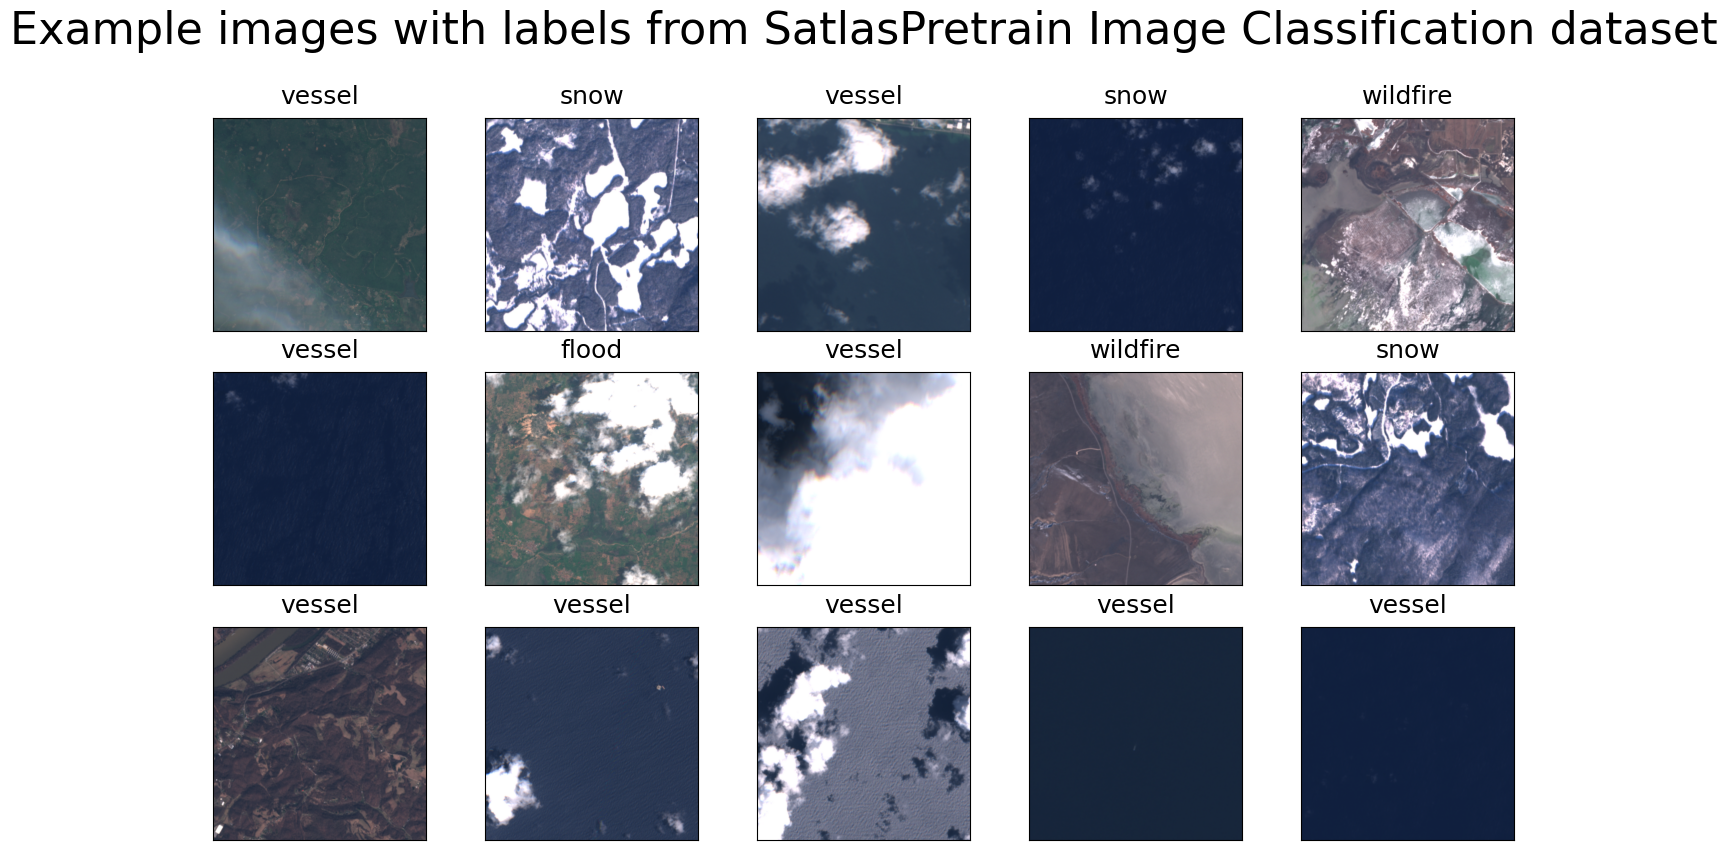

In [47]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [54]:
dataset.show_samples()

,File name,Label
0,sentinel2a/S2A_MSIL1C_20220601T162841_N0400_R0...,vessel
1,sentinel2b/S2B_MSIL1C_20220602T164859_N0400_R0...,vessel
2,sentinel2b/S2B_MSIL1C_20220602T164859_N0400_R0...,vessel
3,sentinel2b/S2B_MSIL1C_20210701T001109_N0301_R0...,vessel
4,sentinel2a/S2A_MSIL1C_20220601T162841_N0400_R0...,vessel
5,sentinel2a/S2A_MSIL1C_20220601T162841_N0400_R0...,vessel
6,sentinel2a/S2A_MSIL1C_20220601T162841_N0400_R0...,vessel
7,sentinel2a/S2A_MSIL1C_20220102T163701_N0301_R0...,snow
8,sentinel2b/S2B_MSIL1C_20220602T164859_N0400_R0...,vessel
9,sentinel2b/S2B_MSIL1C_20220106T205039_N0301_R0...,snow


In [57]:
dataset.data_distribution_table()

,Label,Count
0,flood,52
1,snow,160
2,vessel,276
3,wildfire,94


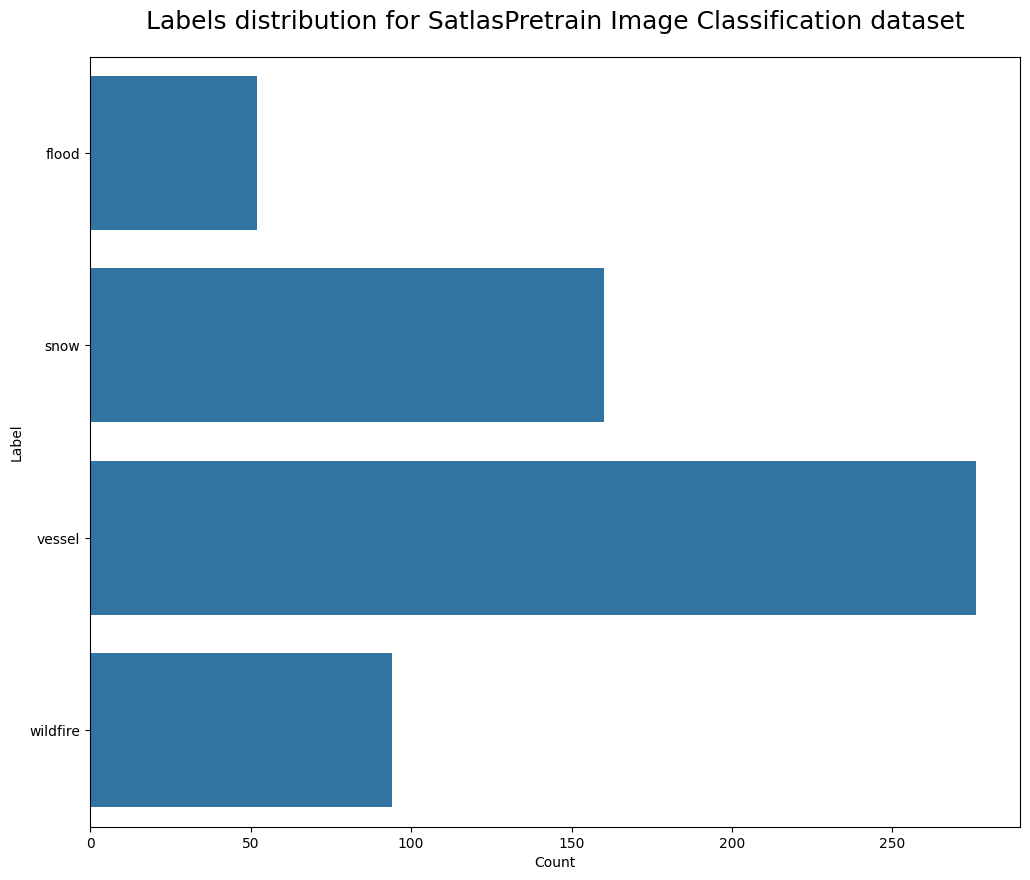

In [58]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [6]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/satlaspretrain_image_classification/",
    "mode": "train",
}

train_dataset = SatlasPretrainImageClassificationDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 3,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/satlaspretrain_image_classification/",
    "mode": "val",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = SatlasPretrainImageClassificationDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(493, 49)

## Setup and create the model for training

In [7]:
epochs = 15
model_directory = "/home/dragik/data/FAIR_EO/experiments/satlas_image_classification/"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-11-10 14:48:03,193 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-11-10 14:48:03,389 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-11-10 14:48:03,448 INFO Starting training.
training: 100%|██████████| 124/124 [00:12<00:00,  9.78it/s]
2025-11-10 14:48:16,371 INFO epoch: 1, time: 13, loss:  0.74080
testing on train set: 100%|██████████| 124/124 [00:05<00:00, 24.27it/s]
2025-11-10 14:48:24,344 INFO Accuracy:0.9087221095334685, Precision Micro:0.9087221095334685, Precision Macro:0.7148268791127168, Precision Weighted:0.9157679555742804, Precision per Class:[0.98795181 0.78431373 0.85064935 0.         0.95121951], Recall Micro:0.9087221095334685, Recall Macro:0.7316674929548064, Recall Weighted:0.9087221095334685, Recall per Class:[0.9010989  0.90909091 0.97761194 0.         0.87053571], F1_score Micro:0.908722109533468, F1_score Macro:0.7206894260206417, F1_score Weighted:0.9094561621412115, F1_score per Class:[0.94252874 0.84210526 0.90972222 0.         0.90909091]
testing on validation set: 100%|██████████| 17/17 [00:00<00:00, 18.52it/s]
2025-11-10 14:48:25,270 INFO Accuracy:0.8979591836734694, Precision Micro:

0.3219788974041448

## Predictions

2025-11-10 14:53:40,445 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/satlas_image_classification/checkpoint.pth.tar
2025-11-10 14:53:41,197 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/satlas_image_classification/checkpoint.pth.tar at epoch 16


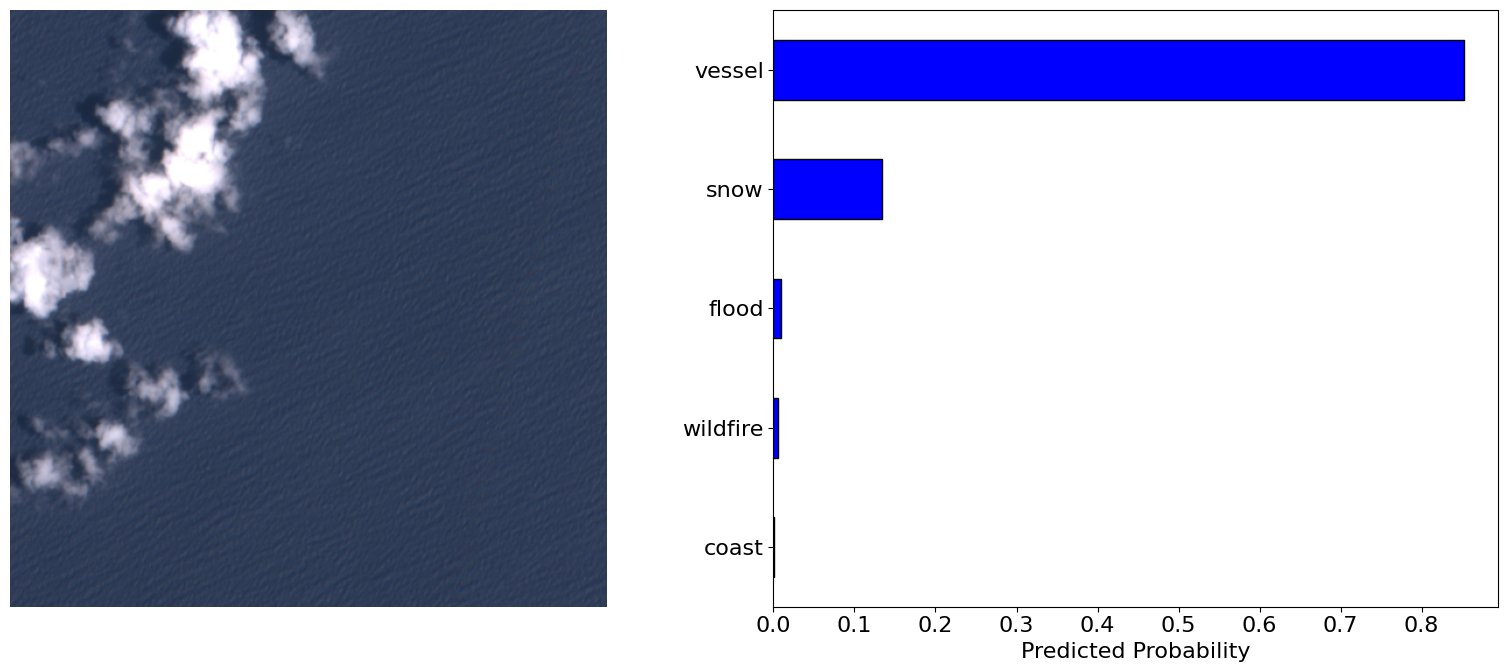

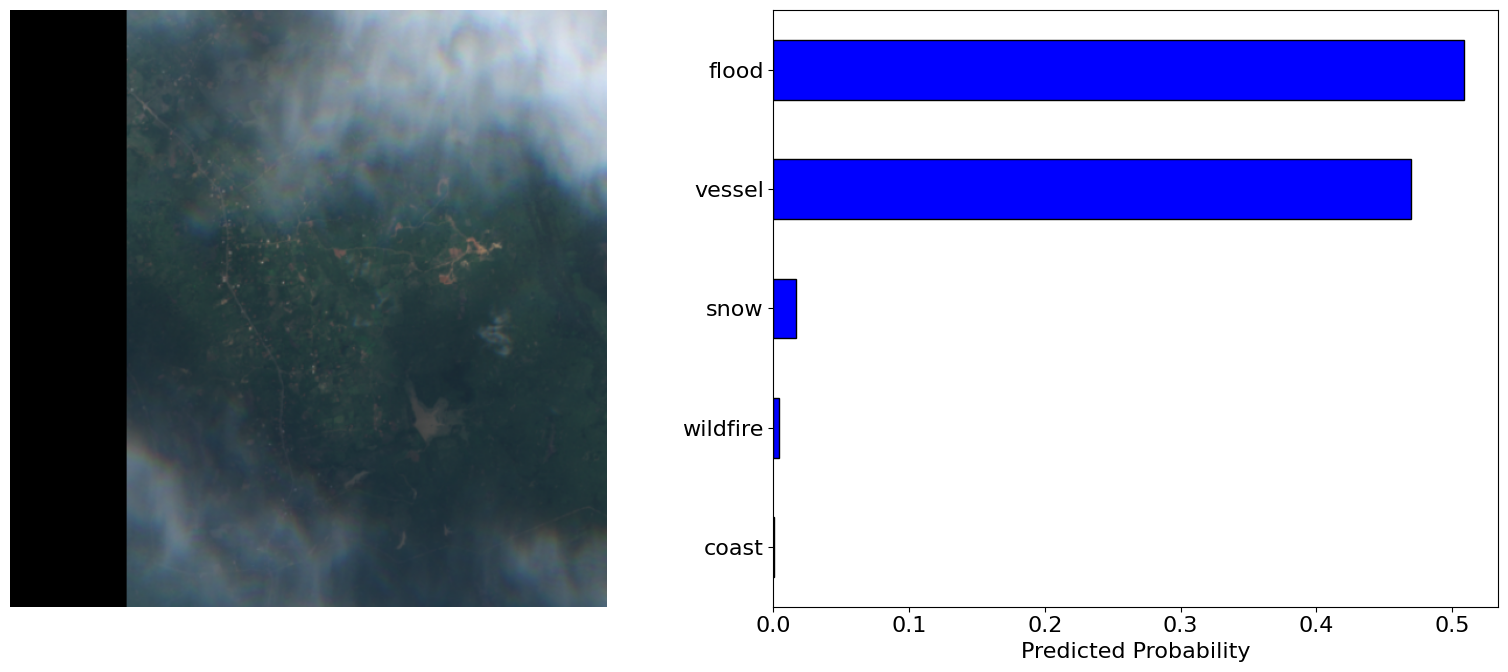

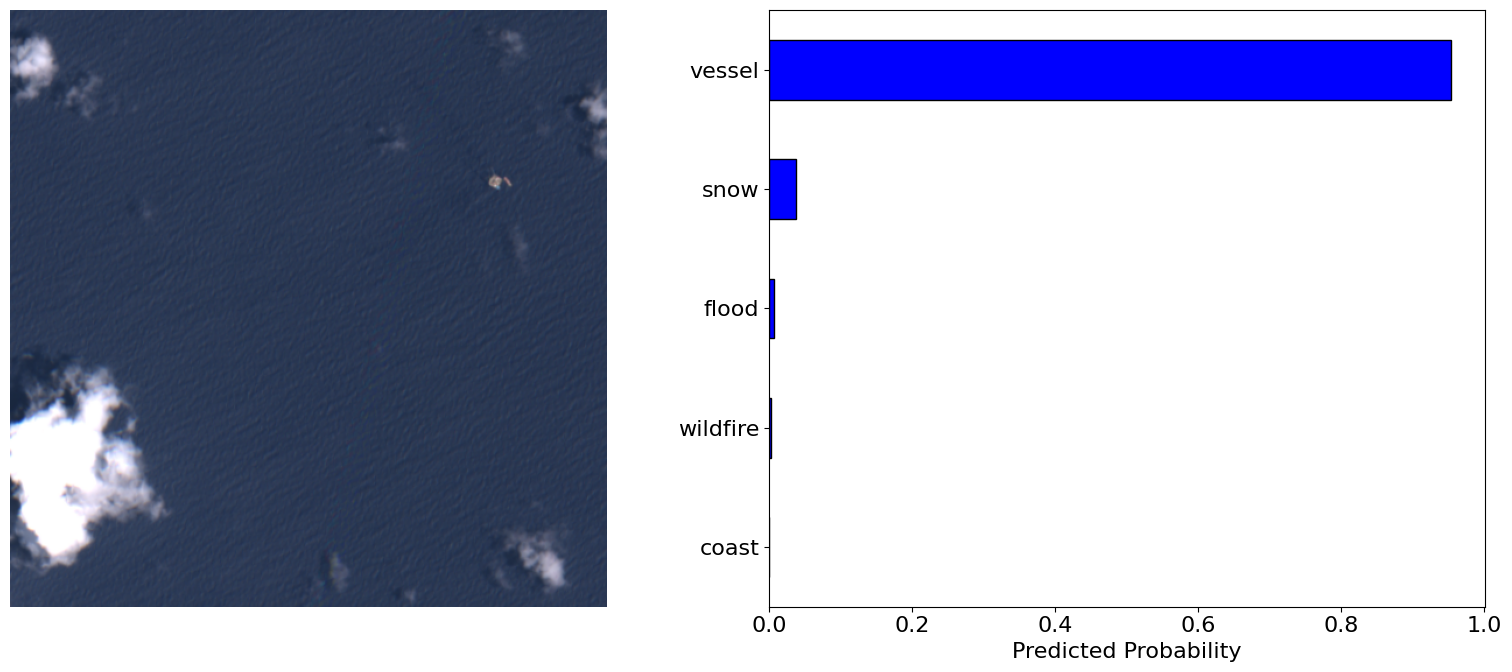

In [ ]:
labels = ['wildfire','flood','snow','coast','vessel']
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/satlas_image_classification/checkpoint.pth.tar"
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/satlaspretrain_image_classification/",
    "mode": "test",
}

test_dataset = SatlasPretrainImageClassificationDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[3][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)